In [ ]:
from pathlib import Path
import platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split, KFold, cross_val_score
from sklearn.metrics import mean_absolute_error

DATA_PATH = Path("toyota.csv")
RANDOM_STATE = 42
numeric_columns = ["year", "mileage", "engineSize", "tax", "mpg"]
categorical_columns = ["model", "transmission", "fuelType"]
rf_settings = dict(
    n_estimators=100,
    max_depth=11,
    min_samples_leaf=3,
    random_state=RANDOM_STATE
)
print("Python:", platform.python_version())
print("pandas:", pd.__version__, "numpy:", np.__version__)
print("matplotlib:", plt.matplotlib.__version__, "scikit-learn:", sklearn.__version__)

Python: 3.13.18
pandas: 2.2.3 numpy: 2.1.3
matplotlib: 3.10.0 scikit-learn: 1.6.1


In [ ]:
df = pd.read_csv(DATA_PATH)
for column in categorical_columns:
    df[column] = df[column].str.strip()

print("元の件数:", len(df))
print("欠損数:")
print(df.isna().sum())
print("完全一致する重複行数:", df.duplicated().sum())
df = df.drop_duplicates().reset_index(drop=True)
print("重複整理後の件数:", len(df))

required_columns = numeric_columns + categorical_columns + ["price"]
if df[required_columns].isna().any().any():
    raise ValueError("欠損があります。欠損の理由と処理方法を確認してください。")
print(df.head().to_string(index=False))
print(df[numeric_columns + ["price"]].describe())

元の件数: 6738
欠損数:
model           0
year            0
price           0
transmission    0
mileage         0
fuelType        0
tax             0
mpg             0
engineSize      0
dtype: int64
完全一致する重複行数: 39
重複整理後の件数: 6699
model  year  price transmission  mileage fuelType  tax  mpg  engineSize
 GT86  2016  16000       Manual    24089   Petrol  265 36.2         2.0
 GT86  2017  15995       Manual    18615   Petrol  145 36.2         2.0
 GT86  2015  13998       Manual    27469   Petrol  265 36.2         2.0
 GT86  2017  18998       Manual    14736   Petrol  150 36.2         2.0
 GT86  2017  17498       Manual    36284   Petrol  145 36.2         2.0
              year        mileage   engineSize          tax          mpg  \
count  6699.000000    6699.000000  6699.000000  6699.000000  6699.000000   
mean   2016.742797   22889.588745     1.471996    94.549933    63.078728   
std       2.205271   19109.288501     0.435624    73.942649    15.861037   
min    1998.000000       2.000000     0.000

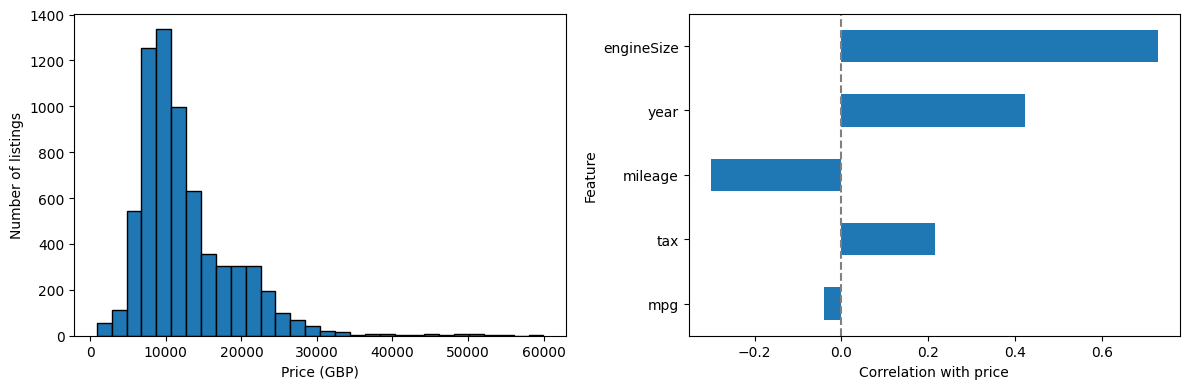

車種ごとの件数:
model
Yaris            2117
Aygo             1940
Auris             709
C-HR              479
RAV4              467
Corolla           265
Prius             232
Avensis           114
Verso             114
Hilux              85
GT86               73
Land Cruiser       51
PROACE VERSO       15
Supra              12
Camry              11
IQ                  8
Urban Cruiser       4
Verso-S             3
Name: count, dtype: int64


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(df["price"], bins=30, edgecolor="black")
axes[0].set(xlabel="Price (GBP)", ylabel="Number of listings")
correlations = df[numeric_columns].corrwith(df["price"])
correlations = correlations.sort_values(key=lambda values: values.abs())
correlations.plot.barh(ax=axes[1])
axes[1].axvline(0, color="gray", linestyle="--")
axes[1].set(xlabel="Correlation with price", ylabel="Feature")
plt.tight_layout()
plt.show()
print("車種ごとの件数:")
print(df["model"].value_counts())

In [ ]:
X = df[numeric_columns + categorical_columns].copy()
y = df["price"].copy()
X_train, X_valid, y_train, y_valid = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE
)

def make_pipeline(model, category_columns, scale_numeric=False):
    transformers = [
        ("numeric", StandardScaler() if scale_numeric else "passthrough", numeric_columns)
    ]
    if category_columns:
        transformers.append((
            "category",
            OneHotEncoder(handle_unknown="ignore", sparse_output=False),
            category_columns
        ))
    preprocessor = ColumnTransformer(transformers=transformers)
    return Pipeline(steps=[("preprocessor", preprocessor), ("model", model)])


def evaluate_model(model, X_train, X_valid, y_train, y_valid):
    model.fit(X_train, y_train)
    prediction = model.predict(X_valid)
    residual = y_valid - prediction
    MAE = mean_absolute_error(y_valid, prediction)
    return MAE, prediction, residual

print("学習件数:", len(X_train), "検証件数:", len(X_valid))

学習件数: 5359 検証件数: 1340


RandomForestRegressor     744.03
LinearRegression         1102.09
Lasso                    1107.06
Ridge                    1110.30
Median baseline          4525.69
Name: MAE_GBP, dtype: float64


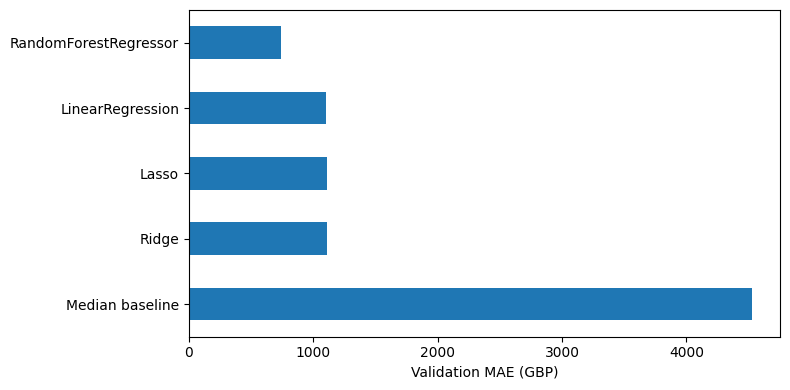

In [ ]:
model_types = {
    "Median baseline": make_pipeline(DummyRegressor(strategy="median"), []),
    "LinearRegression": make_pipeline(LinearRegression(), categorical_columns, True),
    "Ridge": make_pipeline(Ridge(alpha=1.0), categorical_columns, True),
    "Lasso": make_pipeline(Lasso(alpha=1.0, max_iter=20000), categorical_columns, True),
    "RandomForestRegressor": make_pipeline(RandomForestRegressor(**rf_settings), categorical_columns)
}
MAE_results = {}
for model_name, model in model_types.items():
    MAE, prediction, residual = evaluate_model(
        model, X_train, X_valid, y_train, y_valid
    )
    MAE_results[model_name] = MAE

MAE_sorted = pd.Series(MAE_results, name="MAE_GBP").sort_values()
print(MAE_sorted.round(2))
ax = MAE_sorted.plot.barh(figsize=(8, 4))
ax.invert_yaxis()
ax.set_xlabel("Validation MAE (GBP)")
plt.tight_layout()
plt.show()

In [ ]:
feature_sets = {
    "Numeric only": [],
    "+ Model": ["model"],
    "+ Transmission": ["model", "transmission"],
    "+ Fuel type": ["model", "transmission", "fuelType"]
}
feature_MAE_results = {}
for experiment_name, category_columns in feature_sets.items():
    model = make_pipeline(RandomForestRegressor(**rf_settings), category_columns)
    MAE, prediction, residual = evaluate_model(
        model, X_train, X_valid, y_train, y_valid
    )
    feature_MAE_results[experiment_name] = MAE
print(pd.Series(feature_MAE_results, name="MAE_GBP").round(2))

Numeric only      807.98
+ Model           785.42
+ Transmission    753.33
+ Fuel type       744.03
Name: MAE_GBP, dtype: float64


In [ ]:
cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
pipeline = make_pipeline(RandomForestRegressor(**rf_settings), categorical_columns)
baseline_pipeline = make_pipeline(DummyRegressor(strategy="median"), [])

MAE_scores = -cross_val_score(
    pipeline, X, y, cv=cv, scoring="neg_mean_absolute_error", error_score="raise"
)
baseline_scores = -cross_val_score(
    baseline_pipeline, X, y, cv=cv,
    scoring="neg_mean_absolute_error", error_score="raise"
)
cv_results = pd.DataFrame({
    "fold": np.arange(1, 6),
    "RF_MAE_GBP": MAE_scores,
    "baseline_MAE_GBP": baseline_scores
})
print(cv_results.round(2).to_string(index=False))
print(f"平均MAE: {MAE_scores.mean():.2f}ポンド")
print(f"MAEの標準偏差: {MAE_scores.std():.2f}ポンド")
print(f"ベースラインの平均MAE: {baseline_scores.mean():.2f}ポンド")
improvement = (1 - MAE_scores.mean() / baseline_scores.mean()) * 100
print(f"平均MAEの削減率: {improvement:.1f}%")

 fold  RF_MAE_GBP  baseline_MAE_GBP
    1      743.25           4525.69
    2      811.33           4558.25
    3      781.53           4373.24
    4      761.04           4503.84
    5      792.90           4383.49
平均MAE: 778.01ポンド
MAEの標準偏差: 23.83ポンド
ベースラインの平均MAE: 4468.90ポンド
平均MAEの削減率: 82.6%


固定した検証データのMAE: 744.03ポンド


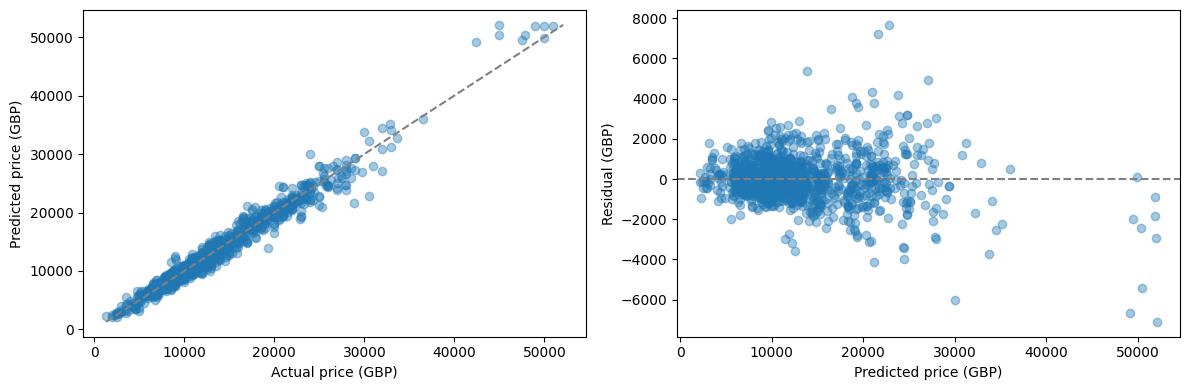

誤差が大きかった車:
 year  mileage  engineSize  tax   mpg        model transmission fuelType  actual_price  predicted_price  residual  absolute_error
 2019       28         2.4  260  40.4        Hilux       Manual   Diesel         30495         22829.07   7665.93         7665.93
 2018    21622         2.4  260  36.2        Hilux    Automatic   Diesel         28850         21651.99   7198.01         7198.01
 2019     4512         2.8  145  30.1 Land Cruiser    Automatic   Diesel         44995         52098.91  -7103.91         7103.91
 2019    10083         2.8  145  30.1 Land Cruiser    Semi-Auto   Diesel         42444         49089.27  -6645.27         6645.27
 2014    53252         3.0  325  34.9 Land Cruiser       Manual   Diesel         23995         30018.31  -6023.31         6023.31
 2020      200         2.8  150  30.1 Land Cruiser    Semi-Auto   Diesel         44995         50424.42  -5429.42         5429.42
 2020     3113         1.5  145  47.9        Yaris    Automatic   Petrol       

In [ ]:
final_pipeline = make_pipeline(RandomForestRegressor(**rf_settings), categorical_columns)
final_MAE, prediction, residual = evaluate_model(
    final_pipeline, X_train, X_valid, y_train, y_valid
)
result = X_valid.copy()
result["actual_price"] = y_valid
result["predicted_price"] = prediction
result["residual"] = residual
result["absolute_error"] = residual.abs()
print(f"固定した検証データのMAE: {final_MAE:.2f}ポンド")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].scatter(y_valid, prediction, alpha=0.4)
limits = [min(y_valid.min(), prediction.min()), max(y_valid.max(), prediction.max())]
axes[0].plot(limits, limits, color="gray", linestyle="--")
axes[0].set(xlabel="Actual price (GBP)", ylabel="Predicted price (GBP)")
axes[1].scatter(prediction, residual, alpha=0.4)
axes[1].axhline(0, color="gray", linestyle="--")
axes[1].set(xlabel="Predicted price (GBP)", ylabel="Residual (GBP)")
plt.tight_layout()
plt.show()

print("誤差が大きかった車:")
print(result.sort_values("absolute_error", ascending=False).head(10).round(2).to_string(index=False))
print("車種別の件数・MAE:")
by_model = result.groupby("model").agg(
    count=("absolute_error", "size"), MAE_GBP=("absolute_error", "mean")
).sort_values("MAE_GBP", ascending=False)
print(by_model.round(2))

result["price_band"] = pd.cut(
    result["actual_price"],
    bins=[0, 10000, 20000, 30000, np.inf],
    labels=["<10k", "10k-20k", "20k-30k", ">=30k"], right=False
)
print("価格帯別の件数・MAE:")
print(result.groupby("price_band", observed=False).agg(
    count=("absolute_error", "size"), MAE_GBP=("absolute_error", "mean")
).round(2))

In [ ]:
print(f"固定検証MAE: {final_MAE:.2f} GBP")
print(f"5分割平均MAE: {MAE_scores.mean():.2f} GBP")
print(f"分割間標準偏差: {MAE_scores.std():.2f} GBP")
print(f"中央値ベースライン比の平均MAE削減率: {improvement:.1f}%")

固定検証MAE: 744.03 GBP
5分割平均MAE: 778.01 GBP
分割間標準偏差: 23.83 GBP
中央値ベースライン比の平均MAE削減率: 82.6%
